In [1]:
import json
import os

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

In [2]:
'''
steps = {'13b': torch.tensor([1100, 5000, 7000, 12000, 19850, 31000, 48000, 72000, 107500, 167000, 239000, 358000, 596057]),
         '1b' : torch.tensor([300, 10000, 23100, 40000, 60000, 90000, 140000, 210000, 330000, 510000, 790000, 1230000, 1907359]),
         '7b': torch.tensor([150, 5000, 11000, 20000, 30000, 45000, 70000, 105000, 165000, 255000, 395000, 615000, 928646])}
peak_lrs = {'13b': 9e-4, '1b': 4e-4, '7b': 3e-4}
total_steps = {'13b': 596057, '1b': 1907359 / 4 * 5, '7b': 928646 / 4 * 5}

taus = {}

def lr_scheduler(step, total_step, peak_lr, warmup_steps = 2000):
    #step = torch.tensor(step)
    mask1 = step < warmup_steps
    lr = (step / warmup_steps * peak_lr) * mask1 + \
        (~mask1) * (0.5 * (1.0 + torch.cos(torch.pi * (step - warmup_steps) / (total_step - warmup_steps))) * 0.9 + 0.1) * peak_lr
    return lr

for k, v in steps.items():
    intergral_steps = torch.arange(1, v[-1]+1)
    lrs = lr_scheduler(intergral_steps, total_steps[k], peak_lrs[k])
    tau = torch.tensor([lrs[:step].sum() for step in v])
    taus[k] = tau
'''

"\nsteps = {'13b': torch.tensor([1100, 5000, 7000, 12000, 19850, 31000, 48000, 72000, 107500, 167000, 239000, 358000, 596057]),\n         '1b' : torch.tensor([300, 10000, 23100, 40000, 60000, 90000, 140000, 210000, 330000, 510000, 790000, 1230000, 1907359]),\n         '7b': torch.tensor([150, 5000, 11000, 20000, 30000, 45000, 70000, 105000, 165000, 255000, 395000, 615000, 928646])}\npeak_lrs = {'13b': 9e-4, '1b': 4e-4, '7b': 3e-4}\ntotal_steps = {'13b': 596057, '1b': 1907359 / 4 * 5, '7b': 928646 / 4 * 5}\n\ntaus = {}\n\ndef lr_scheduler(step, total_step, peak_lr, warmup_steps = 2000):\n    #step = torch.tensor(step)\n    mask1 = step < warmup_steps\n    lr = (step / warmup_steps * peak_lr) * mask1 +         (~mask1) * (0.5 * (1.0 + torch.cos(torch.pi * (step - warmup_steps) / (total_step - warmup_steps))) * 0.9 + 0.1) * peak_lr\n    return lr\n\nfor k, v in steps.items():\n    intergral_steps = torch.arange(1, v[-1]+1)\n    lrs = lr_scheduler(intergral_steps, total_steps[k], peak_lrs[

In [3]:
import re

with open('../results/olmo2_1b_attn_logit_std.jsonl') as f:
    rows = [json.loads(line) for line in f]

rows.sort(key=lambda r: int(re.search(r'step(\d+)', r['revision']).group(1)))

steps = np.array([int(re.search(r'step(\d+)', r['revision']).group(1)) for r in rows])
# attn_std: (n_steps, n_layers, num_heads)
attn_std = np.array([r['attn_logit_std'] for r in rows])
attn_entropy = np.array([r['attn_entropy'] for r in rows])

n_layers, num_heads = attn_std.shape[1], attn_std.shape[2]

# Dynamic time tau — OLMo-2-13B: 2000-step warmup, cosine decay to 0.1*peak_lr, total 596057 steps
TOTAL_STEPS = int(1907359 / 4 * 5)
WARMUP_STEPS = 2000

def lr_scheduler(step, total_steps=TOTAL_STEPS, warmup_steps=WARMUP_STEPS):
    if step < warmup_steps:
        return step / warmup_steps
    progress = (step - warmup_steps) / (total_steps - warmup_steps)
    return 0.5 * (1.0 + np.cos(np.pi * progress)) * 0.9 + 0.1

cache_path = '../cache/olmo1b_lrs_cache.npy'
if os.path.exists(cache_path):
    lrs = np.load(cache_path)
else:
    lrs = np.array([lr_scheduler(s) for s in range(1, TOTAL_STEPS + 1)])
    np.save(cache_path, lrs)

cumsum = np.cumsum(lrs)
tau = cumsum[steps - 1]

print(f'Steps: {steps}')
print(f'attn_std shape: {attn_std.shape}  (n_steps, n_layers, num_heads)')
print(f'attn_entropy shape: {attn_entropy.shape}  (n_steps, n_layers, num_heads)')


Steps: [    300   10000   23100   40000   60000   90000  140000  210000  330000
  510000  790000 1230000 1907359]
attn_std shape: (13, 16, 16)  (n_steps, n_layers, num_heads)
attn_entropy shape: (13, 16, 16)  (n_steps, n_layers, num_heads)


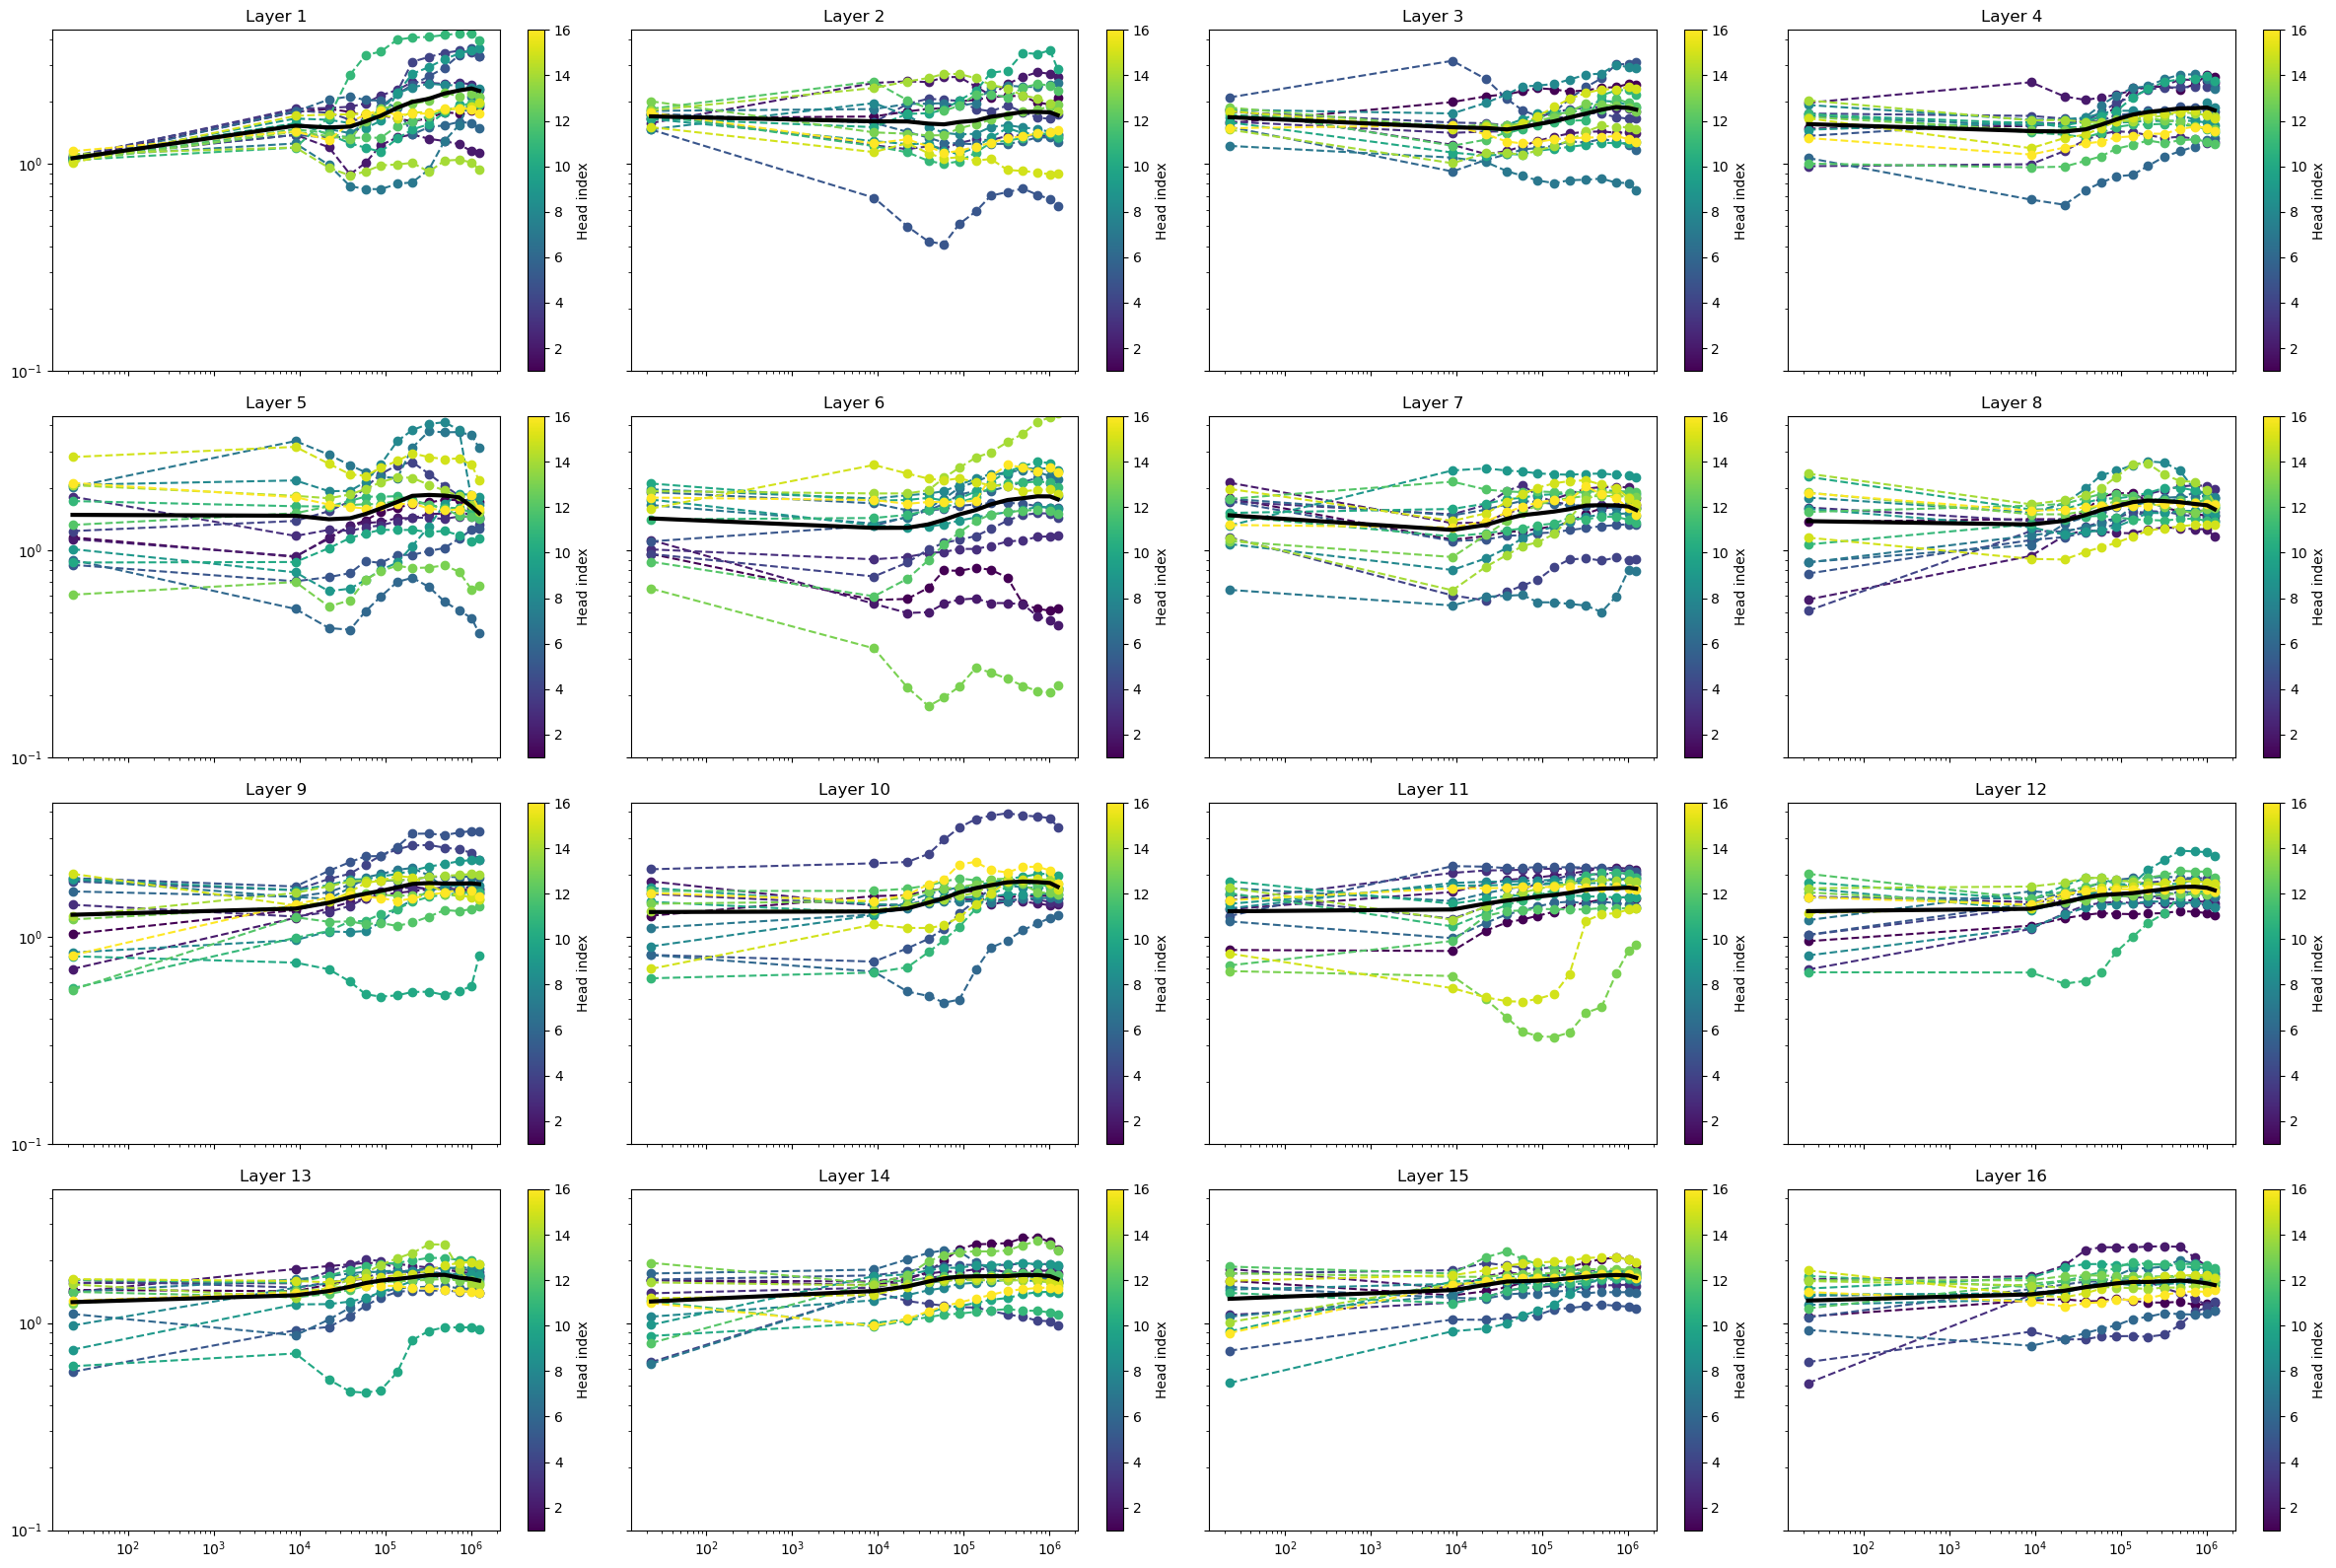

In [4]:
cmap = plt.get_cmap('viridis')
norm = mcolors.Normalize(vmin=1, vmax=num_heads)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
fig, axs = plt.subplots(4, n_layers // 4, figsize=(n_layers * 1.5, 16), sharex = True, sharey = True)
flat_axs = axs.flatten()
for layer in range(n_layers):
    for head in range(num_heads):
        flat_axs[layer].plot(tau, attn_std[:, layer, head], 'o--', color=cmap(head / (num_heads - 1)))
    flat_axs[layer].plot(tau, attn_std[:, layer, :].mean(axis=-1), 'k-', linewidth=3)
    #flat_axs[layer].plot([1e+1,1e+5], [.5, .5 * 1e+4 ** (1/3)], 'r--', linewidth=3)
    flat_axs[layer].set_ylim(1e-1, None)
    flat_axs[layer].set_xscale('log')
    flat_axs[layer].set_yscale('log')
    flat_axs[layer].set_title(f'Layer {layer+1}')
    fig.colorbar(sm, ax=flat_axs[layer], label='Head index')
plt.tight_layout()

The last sharp increase in the norm may be related to smaller lr or river valley? Related to the sharp decrease of loss at the end?

Evaluate our own checkpoints and then larger Pythia models?

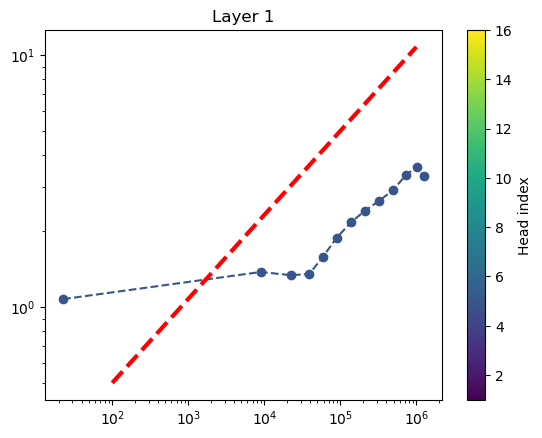

In [19]:
# layer 
layer = 0
for head in [4]:
    plt.plot(tau, attn_std[:, layer, head], 'o--', color=cmap(head / (num_heads - 1)))
plt.plot([1e+2,1e+6], [.5, .5 * 1e+4 ** (1/3)], 'r--', linewidth=3)
plt.xscale('log')
plt.yscale('log')
plt.title(f'Layer {layer+1}')
plt.colorbar(sm, ax=plt.gca(), label='Head index')

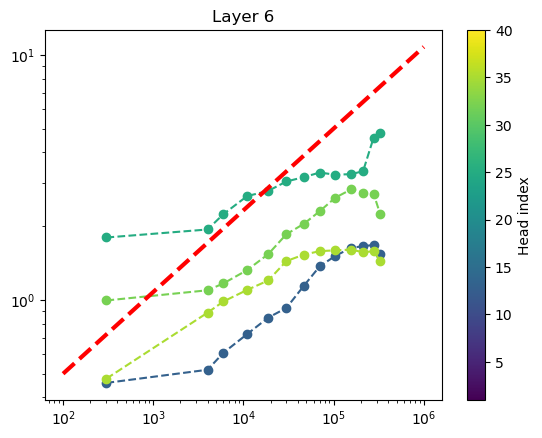

In [7]:
# layer 
layer = 5
for head in [12,24,31,34]:
    plt.plot(tau, attn_std[:, layer, head], 'o--', color=cmap(head / (num_heads - 1)))
plt.plot([1e+2,1e+6], [.5, .5 * 1e+4 ** (1/3)], 'r--', linewidth=3)
plt.xscale('log')
plt.yscale('log')
plt.title(f'Layer {layer+1}')
plt.colorbar(sm, ax=plt.gca(), label='Head index')

Text(0, 0.5, 'Logit std')

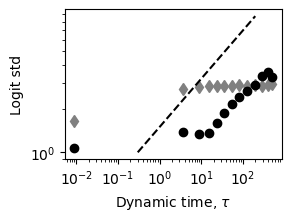

In [22]:
plt.figure(figsize=(2.8, 2.1), constrained_layout=True)
head_logit_std = np.array([1.6512247, 2.7299602, 2.8067276, 2.8565664, 2.8689933, 2.861265 ,
       2.8939338, 2.9303005, 2.8861387, 2.9182632, 2.8622496, 2.9303813,
       2.9695206])
plt.plot(tau * 4e-4, head_logit_std, 'd', color='grey')
plt.plot(tau * 4e-4, attn_std[:,0,4], 'ko')
plt.plot([3e-1,2e+2], [1, 1 * (2e+2/3e-1) ** (1/3)], 'k--')
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'Dynamic time, $\tau$')
plt.ylabel('Logit std')
#plt.savefig('../figures/logit_std_12b.pdf')

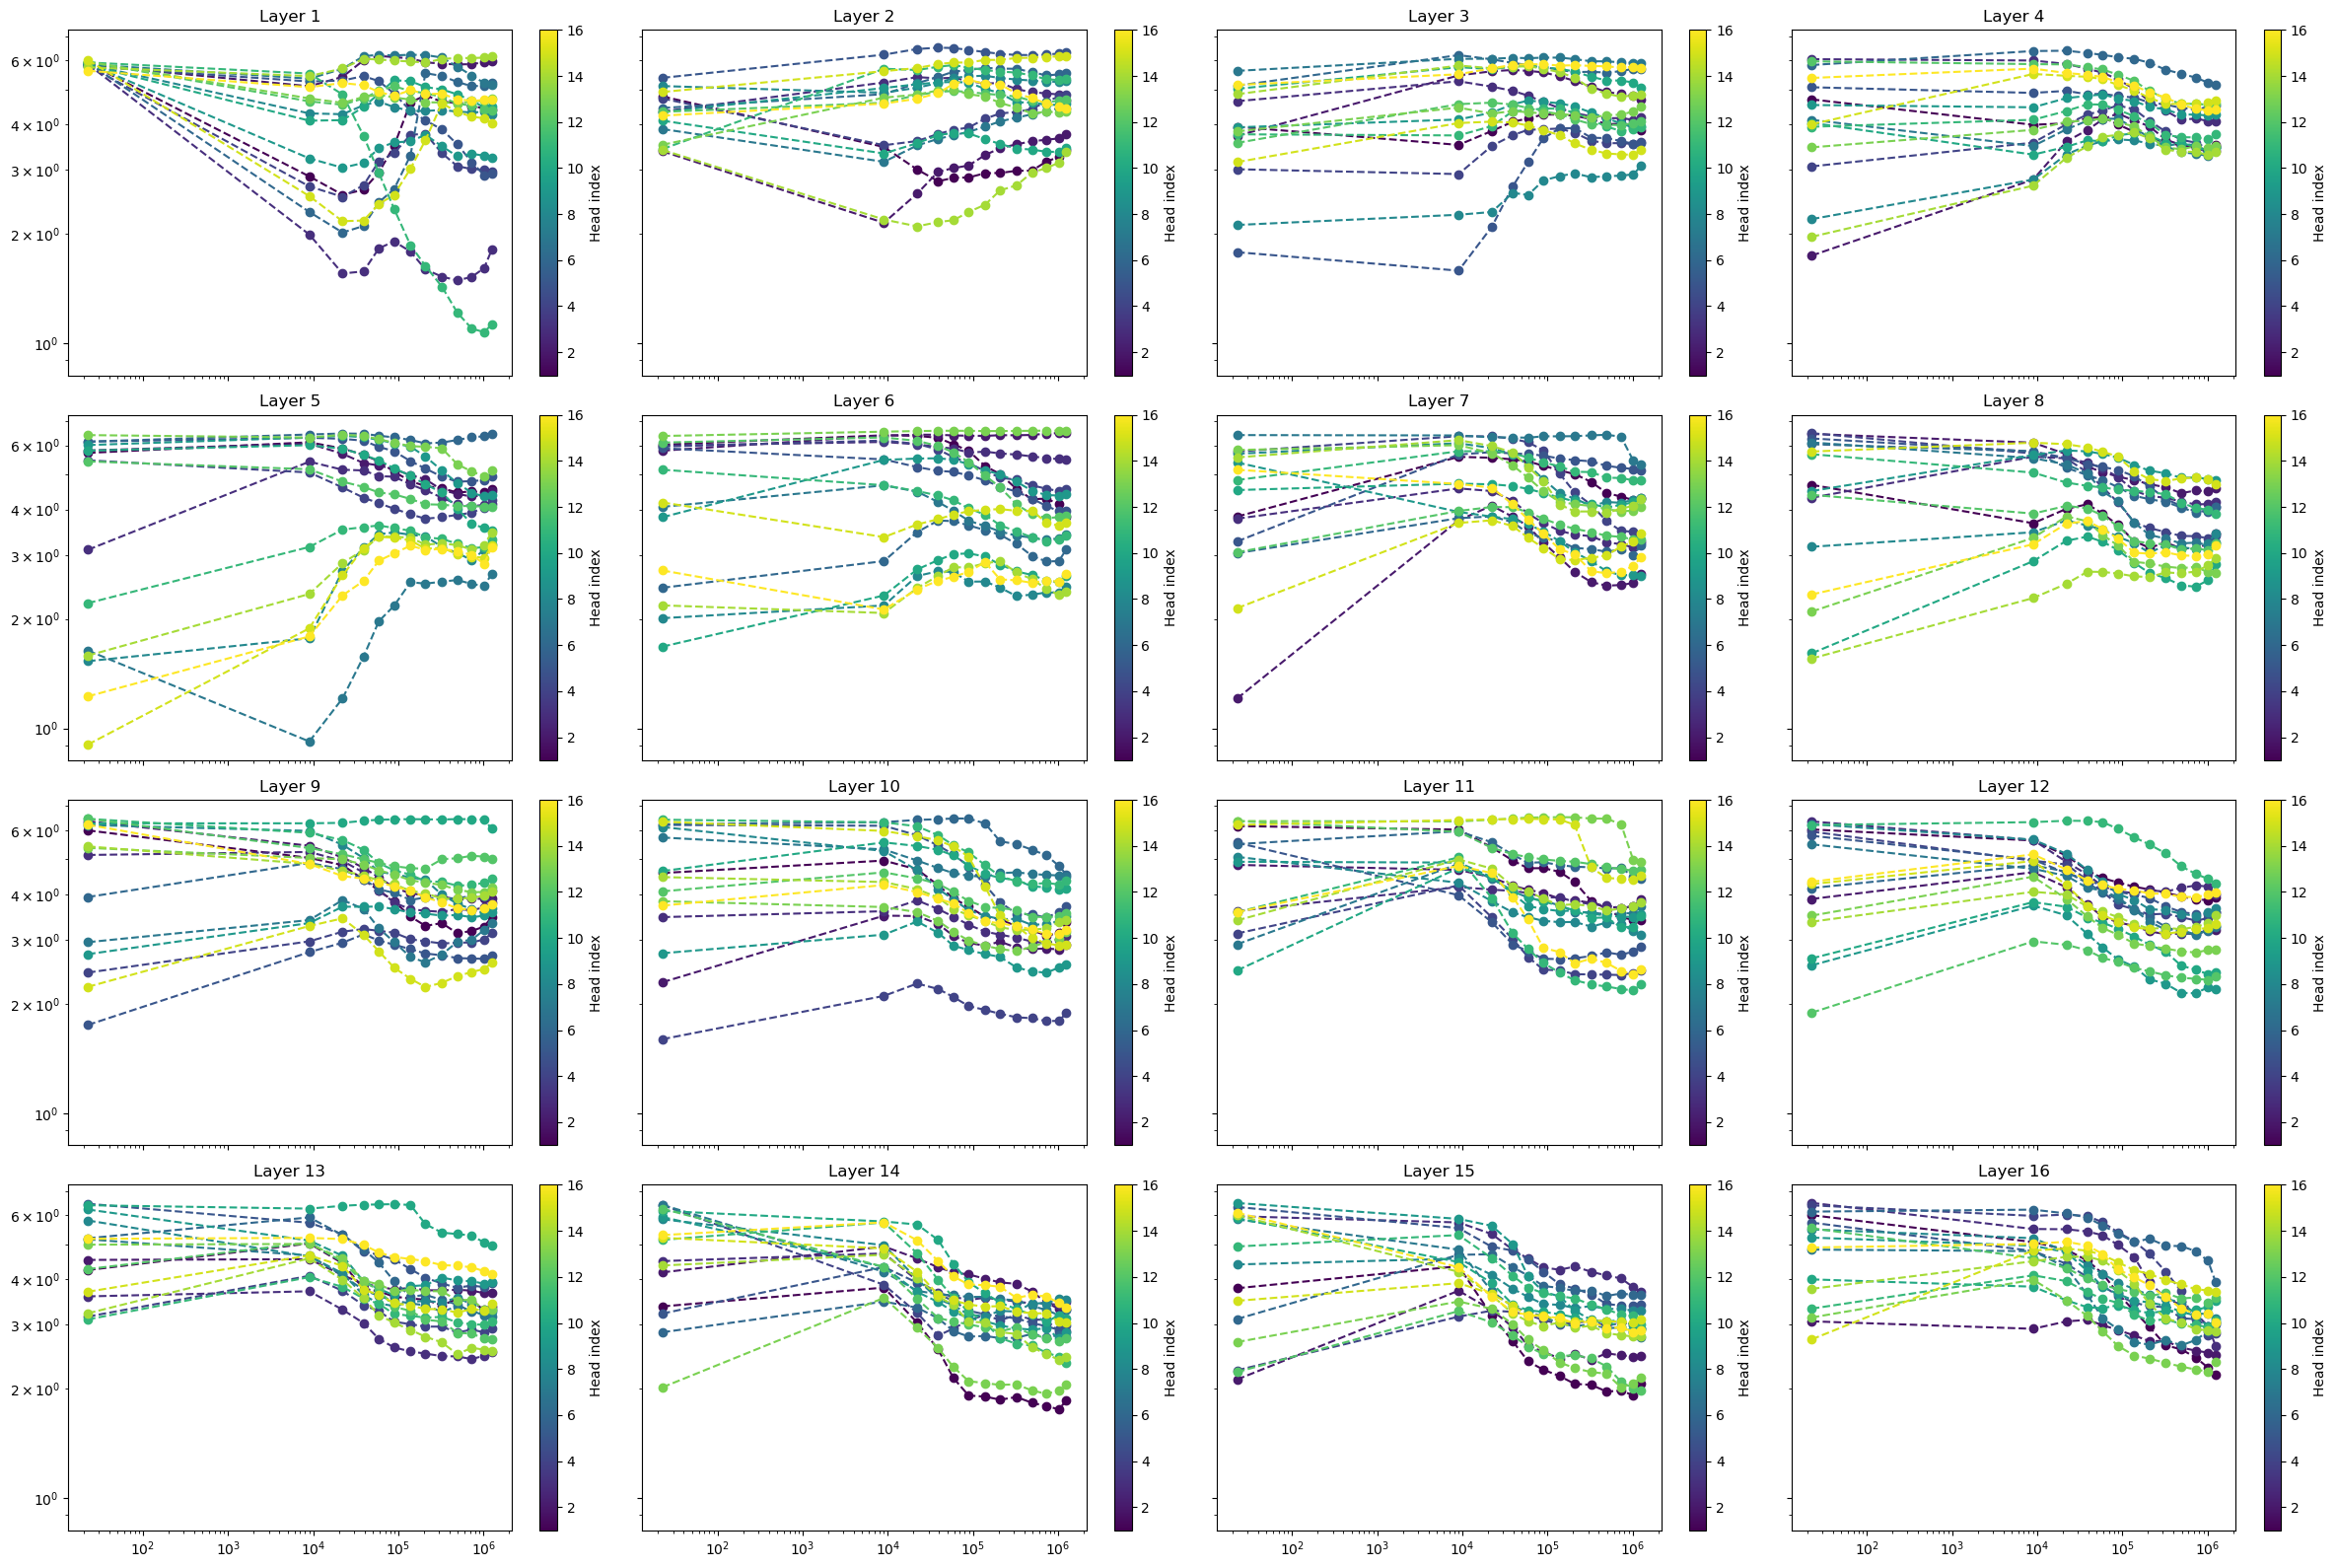

In [5]:
cmap = plt.get_cmap('viridis')
norm = mcolors.Normalize(vmin=1, vmax=num_heads)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
fig, axs = plt.subplots(4, n_layers // 4, figsize=(n_layers * 1.5, 16), sharex = True, sharey = True)
flat_axs = axs.flatten()
for layer in range(n_layers):
    for head in range(num_heads):
        flat_axs[layer].plot(tau, attn_entropy[:, layer, head], 'o--', color=cmap(head / (num_heads - 1)))
    #flat_axs[layer].plot([1e+1,1e+5], [.5, .5 * 1e+4 ** (1/3)], 'r--', linewidth=3)
    flat_axs[layer].set_xscale('log')
    flat_axs[layer].set_yscale('log')
    flat_axs[layer].set_title(f'Layer {layer+1}')
    fig.colorbar(sm, ax=flat_axs[layer], label='Head index')
plt.tight_layout()

In [6]:
def H_gaussian(beta, n_samples = 1024):
    logits = np.random.normal(loc=0.0, scale=beta, size=(n_samples,))
    prob = np.exp(logits - np.max(logits))
    prob /= np.sum(prob)
    return -np.sum(prob * np.log(prob + 1e-12))

H_theory = []
for ctx_len in range(2, 2048):
    beta = np.sqrt(2 * np.log(ctx_len))
    H_theory.append(H_gaussian(beta, ctx_len))
H_theory = np.array(H_theory)
H_t_mean = np.mean(H_theory)
H_head = np.array([H_gaussian(np.sqrt(2 * np.log(32000)), 32000) for i in range(500)]).mean()

Text(0.5, 0, 'Layer')

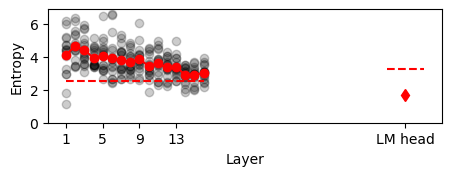

In [7]:
# last point
plt.figure(figsize=(4.4, 1.65), constrained_layout=True)
plt.plot(range(1, n_layers + 1), attn_entropy[-1, :, :], 'o', color='k', alpha = 0.2)
plt.plot(range(1, n_layers + 1), attn_entropy[-1, :, :].mean(axis=1), 'o-', color='r')
plt.plot(range(1, n_layers + 1), H_t_mean * np.ones(n_layers), 'r--')
plt.plot([38], [1.69], 'd', color='r')
plt.plot([36,40], [H_head, H_head], 'r--')
plt.xticks([i for i in range(1, n_layers + 1, 4)]+[38], labels=[str(i) for i in range(1, n_layers + 1, 4)] + ['LM head'])
plt.ylim(0, None)
plt.ylabel(r"Entropy")
plt.xlabel(r"Layer")
#plt.savefig('../figures/attn_entropy_12b.png', dpi=300)

In [9]:
attn_entropy[-1, 0, :]

array([4.4089264 , 5.97062109, 1.81087702, 2.97687571, 2.93892912,
       5.20741886, 5.15370507, 4.27752176, 3.235086  , 4.47241997,
       1.12840466, 4.38494571, 4.70589184, 6.16168838, 4.0356585 ,
       4.68010592])